# The Kang-in Lee Effect — Phase 1: Data Collection

**Business question:** How much *additional* attention did Atlético de Madrid gain in South Korea (and other markets) because of the Kang-in Lee signing — beyond what it would have had anyway?

**What this notebook does (Phase 1 only):** collects, cleans and quality-checks every dataset needed for the causal analysis in Phase 2. It does **not** estimate the effect yet; the charts here are exploratory sanity checks.

| # | Source | Metric | Type |
|---|---|---|---|
| 1 | Wikipedia Pageviews API | Daily views of club & player pages (Korean, Japanese, English Wikipedia) | Absolute counts |
| 2 | Google Trends (`pytrends`) | Search interest by country (KR, US, JP) | Relative index, rescaled across batches |
| 3 | YouTube Data API v3 | Share of **Korean-language comments** on club videos | Audience-composition proxy |
| 4 | Manual capture | Total followers on Instagram / X; manual Instagram comment sample | Sparse snapshots |

### Editorial rules for this project
1. **We measure attention, not revenue.** Shirt sales and commercial income are not public; we never claim them.
2. **No follower-nationality claims.** No free, legitimate tool gives the country of an account's followers over time. We use language of comments as a transparent proxy instead.
3. **Always against a control.** The 2026 World Cup (11 Jun – 19 Jul 2026) boosts football interest in Korea in exactly the same window as the signing. Every series is compared with control clubs that did *not* sign a Korean player.
4. **Privacy.** We store no usernames or author IDs from comments.
5. **Reproducibility.** Raw data is cached to CSV; re-running the notebook does not re-download unless `FORCE_REFRESH = True`.

## 0. Setup

Before running:
- In Colab, open the 🔑 **Secrets** panel (left sidebar) and add a secret named `YOUTUBE_API_KEY` with your key. Enable *Notebook access*. Never paste the key into a code cell.
- Optional: set `USE_DRIVE = True` to save the data in your Google Drive so it survives the Colab session (recommended — the YouTube step may take more than one day of API quota).

In [1]:
!pip install -q pytrends google-api-python-client

In [2]:
import os, re, json, time, math, random, datetime as dt
from pathlib import Path
import urllib.parse

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# ---------- Storage ----------
USE_DRIVE = False          # True = persist data in Google Drive
FORCE_REFRESH = False      # True = ignore cached CSVs and download again

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/kangin_lee_effect')
else:
    BASE_DIR = Path('kangin_lee_effect')

RAW_DIR = BASE_DIR / 'data' / 'raw'
PROC_DIR = BASE_DIR / 'data' / 'processed'
MANUAL_DIR = BASE_DIR / 'data' / 'manual'
FIG_DIR = BASE_DIR / 'figures'
for d in (RAW_DIR, PROC_DIR, MANUAL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print('Saving everything under:', BASE_DIR.resolve())

Saving everything under: /content/kangin_lee_effect


### Study design parameters

All analytical choices live here so they are explicit and easy to change.

- **Window:** from Jan 2022, so Phase 2 can also test the method on Kang-in Lee's previous transfer (Mallorca → PSG, July 2023) as a validation case.
- **Pre-period baseline:** Jan–May 2026 (before rumours intensified and before the World Cup).
- **Event dates:** taken from press coverage. ⚠️ Verify each one against a primary source (club announcement) before publishing.

In [3]:
START_DATE = '2022-01-01'
END_DATE = (dt.date.today() - dt.timedelta(days=1)).isoformat()   # yesterday = last complete day

PRE_PERIOD = ('2026-01-01', '2026-05-31')       # baseline for indexing
FOCUS_WINDOW = ('2026-01-01', END_DATE)         # window for the 2026 charts
WORLD_CUP_2026 = ('2026-06-11', '2026-07-19')   # main confounder

# Event timeline (verify against primary sources before publishing)
EVENTS = {
    '2023-07-08': 'Joins PSG',                    # validation case
    '2026-06-09': 'Atlético push reported',
    '2026-07-06': 'Romano: "here we go"',          # reported in KST
    '2026-07-25': 'Official signing',
}

# Entities: treatment, origin club, validation club, controls and the player himself
ENTITIES = {
    'atletico':      {'label': 'Atlético de Madrid', 'en_wiki': 'Atlético Madrid',          'trends_query': 'Atlético de Madrid', 'group': 'treatment'},
    'psg':           {'label': 'PSG',                'en_wiki': 'Paris Saint-Germain FC',   'trends_query': 'Paris Saint-Germain', 'group': 'origin club'},
    'mallorca':      {'label': 'RCD Mallorca',       'en_wiki': 'RCD Mallorca',             'trends_query': 'RCD Mallorca',       'group': 'validation'},
    'real_madrid':   {'label': 'Real Madrid',        'en_wiki': 'Real Madrid CF',           'trends_query': 'Real Madrid',        'group': 'control'},
    'barcelona':     {'label': 'FC Barcelona',       'en_wiki': 'FC Barcelona',             'trends_query': 'FC Barcelona',       'group': 'control'},
    'real_sociedad': {'label': 'Real Sociedad',      'en_wiki': 'Real Sociedad',            'trends_query': 'Real Sociedad',      'group': 'control'},
    'villarreal':    {'label': 'Villarreal',         'en_wiki': 'Villarreal CF',            'trends_query': 'Villarreal CF',      'group': 'control'},
    'kangin_lee':    {'label': 'Kang-in Lee',        'en_wiki': 'Lee Kang-in',              'trends_query': 'Lee Kang-in',        'group': 'player'},
}
CLUBS = [k for k, v in ENTITIES.items() if v['group'] != 'player']
CONTROLS = [k for k, v in ENTITIES.items() if v['group'] == 'control']

### Chart style

One consistent "newsroom" style: the treated club in its colour, controls in grey, events as vertical lines, the World Cup shaded, and a source line on every chart.

In [4]:
COLORS = {'atletico': '#CB3524', 'psg': '#004170', 'mallorca': '#E8A33D', 'kangin_lee': '#1A1A1A'}
CONTROL_COLOR = '#B5B5B5'

plt.rcParams.update({
    'figure.figsize': (12, 5.5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold',
    'axes.titlesize': 14, 'axes.titlelocation': 'left', 'font.size': 10.5,
    'legend.frameon': False,
})

def color_for(key):
    return COLORS.get(key, CONTROL_COLOR)

def decorate(ax, start=None, end=None, events=True, world_cup=True):
    lo = pd.Timestamp(start) if start else pd.Timestamp.min
    hi = pd.Timestamp(end) if end else pd.Timestamp.max
    if world_cup:
        wc0, wc1 = map(pd.Timestamp, WORLD_CUP_2026)
        if wc1 >= lo and wc0 <= hi:
            ax.axvspan(wc0, wc1, color='#4A90D9', alpha=0.08, lw=0)
            ax.text(wc0, 0.98, ' World Cup 2026', transform=ax.get_xaxis_transform(),
                    va='top', fontsize=8.5, color='#2C6EB5')
    if events:
        for d, label in EVENTS.items():
            ts = pd.Timestamp(d)
            if lo <= ts <= hi:
                ax.axvline(ts, color='#333333', lw=0.8, ls='--', alpha=0.7)
                ax.text(ts, 0.80, ' ' + label, transform=ax.get_xaxis_transform(),
                        rotation=90, va='top', fontsize=8, color='#333333')

def source_note(fig, text):
    fig.text(0.01, -0.01, 'Source: ' + text, fontsize=8.5, color='#666666', ha='left', va='top')

def save_fig(fig, name):
    path = FIG_DIR / f'{name}.png'
    fig.savefig(path, bbox_inches='tight', dpi=200)
    print('Saved', path)

def index_to_baseline(s, period=PRE_PERIOD):
    base = s.loc[period[0]:period[1]].mean()
    return s / base * 100 if base and base > 0 else s * np.nan

In [5]:
# Polite HTTP helper (Wikimedia requires a descriptive User-Agent)
HEADERS = {'User-Agent': 'KanginLeeEffect/1.0 (data portfolio research; contact: your-email@example.com)'}

def get_json(url, params=None, retries=5):
    for attempt in range(retries):
        r = requests.get(url, params=params, headers=HEADERS, timeout=30)
        if r.status_code == 200:
            return r.json()
        if r.status_code == 404:
            return None
        if r.status_code in (429, 500, 502, 503, 504):
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
    raise RuntimeError(f'Failed after {retries} retries: {url}')

def cached(path):
    return Path(path).exists() and not FORCE_REFRESH

## 1. Wikipedia pageviews

**Why it matters:** the cleanest public signal available — absolute daily counts, free, no sampling. Visits to the **Korean-language** article on Atlético de Madrid are a direct measure of Korean-speaking curiosity about the club.

**Method:**
- Article titles in Korean/Japanese are resolved automatically from the English article (interlanguage links), so no title is typed by hand.
- `agent=user` excludes bots and crawlers.
- Days missing from the API mean zero views; they are filled with 0 and counted in the QA table.

**Known limitation:** views that arrive through a redirect are counted under the redirect's title, so the totals are a slight undercount. The undercount is similar for all clubs, so it does not bias the comparison.

In [6]:
WIKI_LANGS = ['ko', 'ja', 'en']

def resolve_wiki_titles(en_title, langs=WIKI_LANGS):
    data = get_json('https://en.wikipedia.org/w/api.php', params={
        'action': 'query', 'titles': en_title, 'prop': 'langlinks', 'lllimit': 'max',
        'redirects': 1, 'format': 'json', 'formatversion': 2})
    page = data['query']['pages'][0]
    if page.get('missing'):
        raise ValueError(f'English article not found: {en_title}')
    titles = {'en': page['title']}
    for ll in page.get('langlinks', []):
        if ll['lang'] in langs:
            titles[ll['lang']] = ll['title']
    return titles

def fetch_pageviews(lang, title, start=START_DATE, end=END_DATE):
    t = urllib.parse.quote(title.replace(' ', '_'), safe='')
    s, e = start.replace('-', ''), end.replace('-', '')
    url = ('https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/'
           f'{lang}.wikipedia.org/all-access/user/{t}/daily/{s}00/{e}00')
    data = get_json(url)
    full_range = pd.date_range(start, end, freq='D')
    if not data or 'items' not in data:
        return pd.Series(0, index=full_range, name='views'), 0
    s_ = pd.Series({pd.to_datetime(i['timestamp'][:8]): i['views'] for i in data['items']})
    n_present = len(s_)
    return s_.reindex(full_range, fill_value=0).rename('views'), n_present

In [7]:
WIKI_PATH = RAW_DIR / 'wikipedia_pageviews.csv'
TITLES_PATH = RAW_DIR / 'wikipedia_titles.json'

if cached(WIKI_PATH):
    wiki = pd.read_csv(WIKI_PATH, parse_dates=['date'])
    print('Loaded cached', WIKI_PATH)
else:
    titles_map, frames = {}, []
    for key, meta in ENTITIES.items():
        titles = resolve_wiki_titles(meta['en_wiki'])
        titles_map[key] = titles
        for lang in WIKI_LANGS:
            if lang not in titles:
                print(f'  ⚠️ {key}: no {lang} article')
                continue
            series, n_present = fetch_pageviews(lang, titles[lang])
            frames.append(pd.DataFrame({
                'date': series.index, 'entity': key, 'lang': lang,
                'title': titles[lang], 'views': series.values,
                'api_days_present': n_present}))
            time.sleep(0.2)
        print(f'✓ {key}: {titles}')
    wiki = pd.concat(frames, ignore_index=True)
    wiki.to_csv(WIKI_PATH, index=False)
    TITLES_PATH.write_text(json.dumps(titles_map, ensure_ascii=False, indent=2))

wiki.head()

✓ atletico: {'en': 'Atlético Madrid', 'ja': 'アトレティコ・マドリード', 'ko': '아틀레티코 마드리드'}
✓ psg: {'en': 'Paris Saint-Germain FC', 'ja': 'パリ・サンジェルマンFC', 'ko': '파리 생제르맹 FC'}
✓ mallorca: {'en': 'RCD Mallorca', 'ja': 'RCDマジョルカ', 'ko': 'RCD 마요르카'}
✓ real_madrid: {'en': 'Real Madrid CF', 'ja': 'レアル・マドリード', 'ko': '레알 마드리드 CF'}
✓ barcelona: {'en': 'FC Barcelona', 'ja': 'FCバルセロナ', 'ko': 'FC 바르셀로나'}
✓ real_sociedad: {'en': 'Real Sociedad', 'ja': 'レアル・ソシエダ', 'ko': '레알 소시에다드'}
✓ villarreal: {'en': 'Villarreal CF', 'ja': 'ビジャレアルCF', 'ko': '비야레알 CF'}
✓ kangin_lee: {'en': 'Lee Kang-in', 'ja': '李康仁', 'ko': '이강인'}


,date,entity,lang,title,views,api_days_present
0,2022-01-01,atletico,ko,아틀레티코 마드리드,25,1766
1,2022-01-02,atletico,ko,아틀레티코 마드리드,25,1766
2,2022-01-03,atletico,ko,아틀레티코 마드리드,22,1766
3,2022-01-04,atletico,ko,아틀레티코 마드리드,19,1766
4,2022-01-05,atletico,ko,아틀레티코 마드리드,12,1766


### QA: coverage and plausibility
Check that every entity/language has data for the whole window. Many zero days for a big club would point to a wrong title or a page rename, not to a lack of interest.

In [8]:
qa_wiki = (wiki.groupby(['entity', 'lang'])
               .agg(title=('title', 'first'),
                    total_views=('views', 'sum'),
                    median_daily=('views', 'median'),
                    zero_days=('views', lambda v: int((v == 0).sum())),
                    days=('views', 'size'))
               .assign(zero_share=lambda d: (d.zero_days / d.days).round(3))
               .sort_values(['lang', 'total_views'], ascending=[True, False]))
display(qa_wiki)

flag = qa_wiki[(qa_wiki.zero_share > 0.05) & (qa_wiki.median_daily > 20)]
print('⚠️ Suspicious series (many zero days despite high median):' if len(flag) else '✓ No suspicious series.')
if len(flag): display(flag)

,,title,total_views,median_daily,zero_days,days,zero_share
entity,lang,,,,,,
real_madrid,en,Real Madrid CF,28291537,12947.0,0,1766,0.000
barcelona,en,FC Barcelona,25461928,11982.5,0,1766,0.000
atletico,en,Atlético Madrid,7959006,3697.5,0,1766,0.000
psg,en,Paris Saint-Germain FC,5075376,12.5,32,1766,0.018
villarreal,en,Villarreal CF,3671551,1514.5,0,1766,0.000
real_sociedad,en,Real Sociedad,3549594,1555.0,0,1766,0.000
kangin_lee,en,Lee Kang-in,2441412,742.5,0,1766,0.000
mallorca,en,RCD Mallorca,1692068,819.5,0,1766,0.000
real_madrid,ja,レアル・マドリード,2130710,948.0,0,1766,0.000


✓ No suspicious series.


### Exploratory chart 1 — Korean Wikipedia, 2026 (indexed to Jan–May = 100)
Indexing removes the size difference between Real Madrid and Real Sociedad so we compare **growth**, not size. 7-day rolling average to remove weekday noise.

Saved kangin_lee_effect/figures/01_ko_wikipedia_clubs_indexed.png


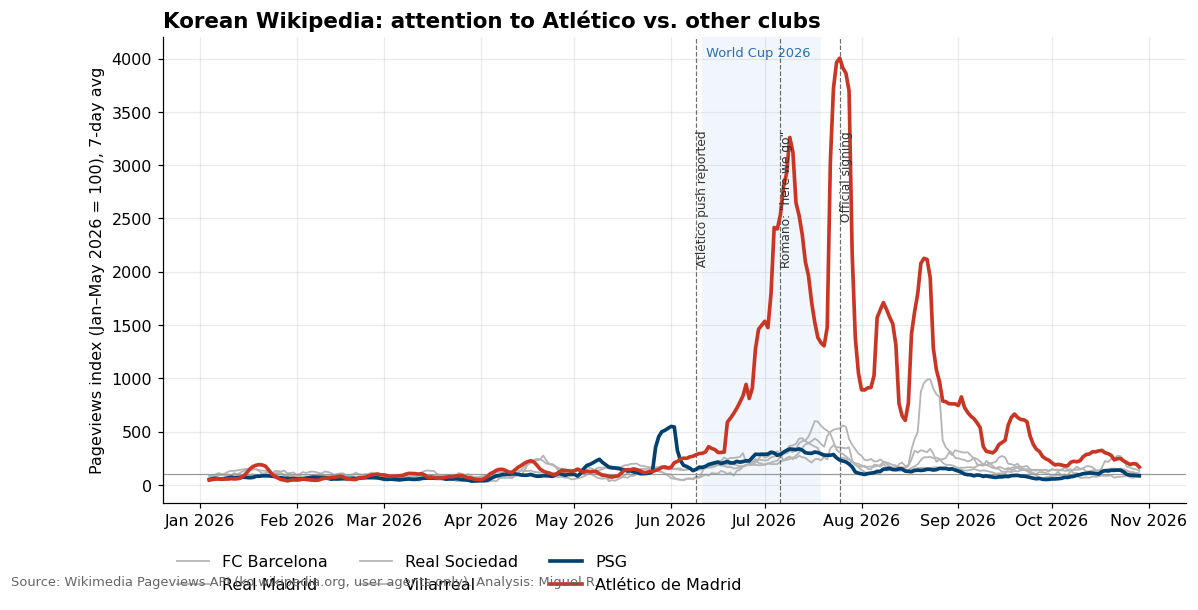

In [9]:
ko = (wiki[wiki.lang == 'ko'].pivot_table(index='date', columns='entity', values='views')
          .loc[FOCUS_WINDOW[0]:FOCUS_WINDOW[1]])
ko_idx = ko.apply(index_to_baseline).rolling(7, center=True).mean()

fig, ax = plt.subplots()
order = [c for c in ko_idx.columns if c not in COLORS] + [c for c in ['psg', 'atletico'] if c in ko_idx.columns]
for col in order:
    if col in ('kangin_lee', 'mallorca'):
        continue
    is_hi = col in COLORS
    ax.plot(ko_idx.index, ko_idx[col], color=color_for(col), lw=2.4 if is_hi else 1.2,
            label=ENTITIES[col]['label'], zorder=3 if is_hi else 2)
decorate(ax, *FOCUS_WINDOW)
ax.axhline(100, color='#999999', lw=0.8)
ax.set_title('Korean Wikipedia: attention to Atlético vs. other clubs')
ax.set_ylabel('Pageviews index (Jan–May 2026 = 100), 7-day avg')
ax.legend(ncol=3, loc='upper left', bbox_to_anchor=(0, -0.08))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
source_note(fig, 'Wikimedia Pageviews API (ko.wikipedia.org, user agents only). Analysis: Miguel R.')
save_fig(fig, '01_ko_wikipedia_clubs_indexed')
plt.show()

### Exploratory chart 2 — Player vs. club
Does attention to Atlético move with attention to Kang-in Lee himself? If the club line only moves when the player line moves, that is the first hint that **the commercial asset is the player**.

Saved kangin_lee_effect/figures/02_ko_wikipedia_player_vs_club.png


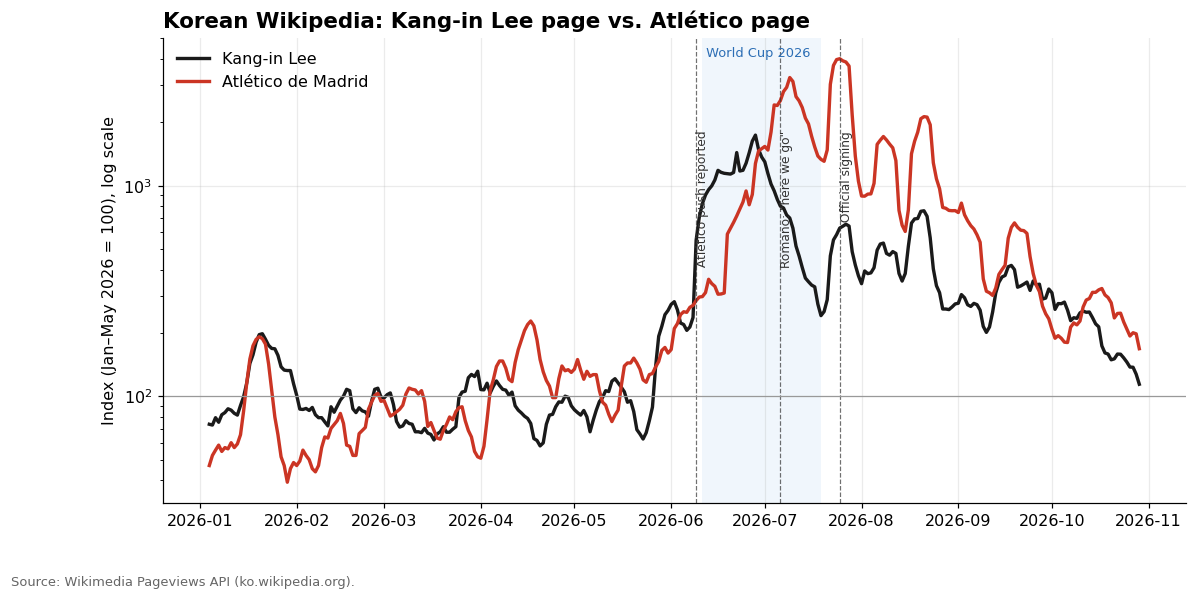

In [10]:
fig, ax = plt.subplots()
for col in ['kangin_lee', 'atletico']:
    if col in ko_idx:
        ax.plot(ko_idx.index, ko_idx[col], color=color_for(col), lw=2.2, label=ENTITIES[col]['label'])
decorate(ax, *FOCUS_WINDOW)
ax.axhline(100, color='#999999', lw=0.8)
ax.set_yscale('log')
ax.set_title('Korean Wikipedia: Kang-in Lee page vs. Atlético page')
ax.set_ylabel('Index (Jan–May 2026 = 100), log scale')
ax.legend(loc='upper left')
source_note(fig, 'Wikimedia Pageviews API (ko.wikipedia.org).')
save_fig(fig, '02_ko_wikipedia_player_vs_club')
plt.show()

### Exploratory chart 3 — Validation case: Mallorca → PSG (summer 2023)
If the same pattern appears when he moved to PSG, the 2026 finding is not a one-off.

Saved kangin_lee_effect/figures/03_validation_2023_psg.png


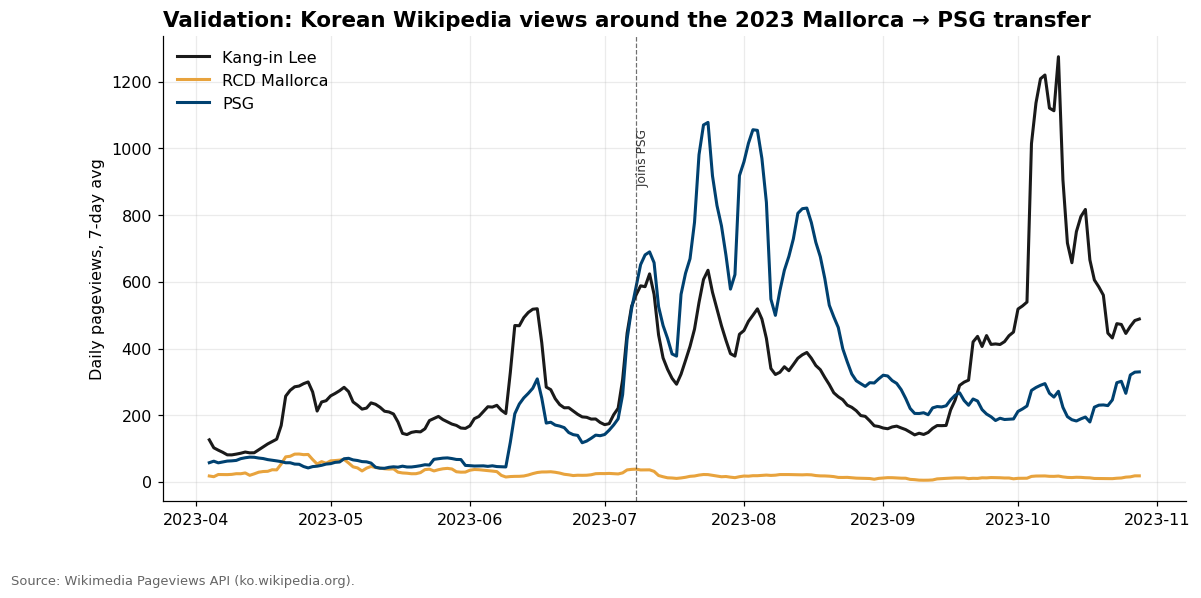

In [11]:
win23 = ('2023-04-01', '2023-10-31')
ko23 = wiki[(wiki.lang == 'ko') & wiki.entity.isin(['psg', 'mallorca', 'kangin_lee'])] \
         .pivot_table(index='date', columns='entity', values='views').loc[win23[0]:win23[1]] \
         .rolling(7, center=True).mean()

fig, ax = plt.subplots()
for col in ko23.columns:
    ax.plot(ko23.index, ko23[col], color=color_for(col), lw=2, label=ENTITIES[col]['label'])
decorate(ax, *win23, world_cup=False)
ax.set_title('Validation: Korean Wikipedia views around the 2023 Mallorca → PSG transfer')
ax.set_ylabel('Daily pageviews, 7-day avg')
ax.legend(loc='upper left')
source_note(fig, 'Wikimedia Pageviews API (ko.wikipedia.org).')
save_fig(fig, '03_validation_2023_psg')
plt.show()

## 2. Google Trends

**Why it matters:** search interest is a broader signal than Wikipedia, and it is comparable across countries (KR, US, JP).

**Three rigour decisions:**
1. **Topics, not keywords.** We query Google's *topic* entities (e.g. "Atlético de Madrid — Football club") instead of text strings. A topic aggregates searches in any language and spelling (아틀레티코, Atleti, Atlético Madrid…). Check the printed topic list before continuing.
2. **Anchor-based rescaling.** Trends allows max 5 terms per request and scales each request 0–100 independently. Real Madrid is included in **every** batch as an anchor, and all batches are rescaled to the anchor's level, so the series become comparable.
3. **Two granularities.** Weekly for the long window (2022 → today), daily for Apr 2026 → today (Google only returns daily data for windows under ~9 months).

⚠️ `pytrends` is an unofficial library and Google often rate-limits it (error 429). The code retries with increasing waits. If it still fails, use the **manual fallback** at the end of this section (downloading CSVs from trends.google.com takes about 10 minutes).

In [12]:
from pytrends.request import TrendReq

pytrends = TrendReq(hl='en-US', tz=-540, timeout=(10, 30))   # tz in minutes: KST = UTC+9

TRENDS_GEOS = ['KR', 'US', 'JP']
ANCHOR = 'real_madrid'
TREND_TIMEFRAMES = {
    'weekly': f'{START_DATE} {END_DATE}',
    'daily':  f'2026-04-01 {END_DATE}',
}

# If the automatic choice below is wrong, paste the correct topic id ('mid') here, e.g. {'mallorca': '/m/0xxxx'}
TOPIC_OVERRIDES = {}

def resolve_topic(key, query, wanted_types=('club', 'football', 'soccer', 'player', 'footballer')):
    if key in TOPIC_OVERRIDES:
        return TOPIC_OVERRIDES[key], 'manual override'
    sugg = pytrends.suggestions(query)
    for s in sugg:
        if any(w in s.get('type', '').lower() for w in wanted_types):
            return s['mid'], f"{s['title']} — {s['type']}"
    if sugg:
        return sugg[0]['mid'], f"{sugg[0]['title']} — {sugg[0].get('type', '?')} (fallback, check!)"
    raise ValueError(f'No topic found for {query}')

TOPICS, topic_log = {}, []
for key, meta in ENTITIES.items():
    mid, desc = resolve_topic(key, meta['trends_query'])
    TOPICS[key] = mid
    topic_log.append({'entity': key, 'mid': mid, 'topic': desc})
    time.sleep(1.5)
topic_log = pd.DataFrame(topic_log)
display(topic_log)   # ← CHECK: every row must be the football club / the player

,entity,mid,topic
0,atletico,/m/0lg7v,Atlético Madrid — Soccer club
1,psg,/m/01_1kk,Paris Saint-Germain F.C. — Soccer club
2,mallorca,/m/01vqc7,RCD Mallorca — Soccer club
3,real_madrid,/m/06l22,Real Madrid — Soccer club
4,barcelona,/m/0hvgt,FC Barcelona — Soccer club
5,real_sociedad,/m/0122wc,Real Sociedad — Football club
6,villarreal,/m/03tck1,Villarreal CF — Soccer club
7,kangin_lee,/g/113qbsflh,Lee Kang-in — South Korean soccer player


In [13]:
def trends_request(keys, geo, timeframe, max_attempts=6):
    kw = [TOPICS[k] for k in keys]
    for attempt in range(max_attempts):
        try:
            pytrends.build_payload(kw, timeframe=timeframe, geo=geo)
            df = pytrends.interest_over_time()
            if df.empty:
                return pd.DataFrame(columns=keys)
            df = df.drop(columns='isPartial', errors='ignore')
            return df.rename(columns=dict(zip(kw, keys)))
        except Exception as e:
            wait = 30 * (attempt + 1) + random.uniform(0, 10)
            print(f'   {type(e).__name__} → waiting {wait:.0f}s (attempt {attempt + 1}/{max_attempts})')
            time.sleep(wait)
    return None

def rescale_batches(batches, anchor=ANCHOR):
    # Put every batch on the scale of the first batch using the anchor's total
    ref = batches[0][anchor].astype(float).sum()
    out = []
    for b in batches:
        a = b[anchor].astype(float).sum()
        factor = ref / a if a > 0 else np.nan
        out.append(b.drop(columns=anchor).astype(float) * factor)
    result = pd.concat(out, axis=1)
    result[anchor] = batches[0][anchor].astype(float)
    return result

others = [k for k in ENTITIES if k != ANCHOR]
BATCHES = [others[i:i + 4] for i in range(0, len(others), 4)]   # 4 entities + anchor per request
print('Batches:', BATCHES)

Batches: [['atletico', 'psg', 'mallorca', 'barcelona'], ['real_sociedad', 'villarreal', 'kangin_lee']]


In [14]:
TRENDS_PATH = RAW_DIR / 'google_trends.csv'

if cached(TRENDS_PATH):
    trends = pd.read_csv(TRENDS_PATH, parse_dates=['date'])
    print('Loaded cached', TRENDS_PATH)
else:
    frames, failed = [], []
    for geo in TRENDS_GEOS:
        for gran, tf in TREND_TIMEFRAMES.items():
            print(f'→ {geo} | {gran} | {tf}')
            batches = []
            for b in BATCHES:
                df = trends_request(b + [ANCHOR], geo, tf)
                if df is None:
                    failed.append((geo, gran, b))
                    break
                batches.append(df)
                time.sleep(15 + random.uniform(0, 5))
            if len(batches) != len(BATCHES):
                continue
            wide = rescale_batches(batches)
            long = (wide.reset_index().melt(id_vars='date', var_name='entity', value_name='interest')
                        .assign(geo=geo, granularity=gran))
            frames.append(long)
    trends = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(
        columns=['date', 'entity', 'interest', 'geo', 'granularity'])
    trends.to_csv(TRENDS_PATH, index=False)
    print('✓ Saved' if not failed else f'⚠️ Failed requests (use manual fallback): {failed}')

trends.groupby(['geo', 'granularity']).entity.nunique()

→ KR | weekly | 2022-01-01 2026-11-01


/usr/local/lib/python3.13/dist-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)
/usr/local/lib/python3.13/dist-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


→ KR | daily | 2026-04-01 2026-11-01
→ US | weekly | 2022-01-01 2026-11-01


/usr/local/lib/python3.13/dist-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)
/usr/local/lib/python3.13/dist-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


→ US | daily | 2026-04-01 2026-11-01
→ JP | weekly | 2022-01-01 2026-11-01


/usr/local/lib/python3.13/dist-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)
/usr/local/lib/python3.13/dist-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


→ JP | daily | 2026-04-01 2026-11-01
✓ Saved


geo  granularity
JP   daily          8
     weekly         8
KR   daily          8
     weekly         8
US   daily          8
     weekly         8
Name: entity, dtype: int64

### Manual fallback (only if `pytrends` was blocked)
1. Go to trends.google.com → *Explore*, choose the country and the date range.
2. Add **topics** (pick the option labelled "Football club" / "Footballer" in the dropdown, not the plain search term): Real Madrid + up to 4 others.
3. Download the CSV and upload it to `data/manual/trends/` with the name `{GEO}_{granularity}_{n}.csv`, e.g. `KR_daily_1.csv`.
4. Run the cell below. Column names are matched to entities by label, so keep Real Madrid in every file.

In [15]:
def parse_trends_csv(path):
    lines = Path(path).read_text(encoding='utf-8-sig').splitlines()
    start = next(i for i, l in enumerate(lines) if l.split(',')[0].strip() in ('Week', 'Day', 'Time', 'Month'))
    from io import StringIO
    df = pd.read_csv(StringIO('\n'.join(lines[start:])))
    df = df.rename(columns={df.columns[0]: 'date'})
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date').replace('<1', 0.5).astype(float)
    # match columns such as 'Atlético de Madrid: (South Korea)' to entity keys
    mapping = {}
    for col in df.columns:
        for key, meta in ENTITIES.items():
            if meta['label'].lower().split()[0] in col.lower() or meta['trends_query'].lower() in col.lower():
                mapping[col] = key
                break
    return df.rename(columns=mapping)

manual_files = sorted((MANUAL_DIR / 'trends').glob('*.csv')) if (MANUAL_DIR / 'trends').exists() else []
if manual_files:
    groups = {}
    for f in manual_files:
        geo, gran, _ = f.stem.split('_')
        groups.setdefault((geo, gran), []).append(parse_trends_csv(f))
    frames = []
    for (geo, gran), batches in groups.items():
        wide = rescale_batches(batches)
        frames.append(wide.reset_index().melt(id_vars='date', var_name='entity', value_name='interest')
                          .assign(geo=geo, granularity=gran))
    trends = pd.concat(frames, ignore_index=True)
    trends.to_csv(TRENDS_PATH, index=False)
    print('✓ Manual Trends data loaded:', trends.groupby(['geo', 'granularity']).size().to_dict())
else:
    print('No manual files — skipping (fine if the automatic download worked).')

No manual files — skipping (fine if the automatic download worked).


### Exploratory chart 4 — Search interest in South Korea, daily (Apr 2026 → today)

Saved kangin_lee_effect/figures/04_trends_kr_daily.png


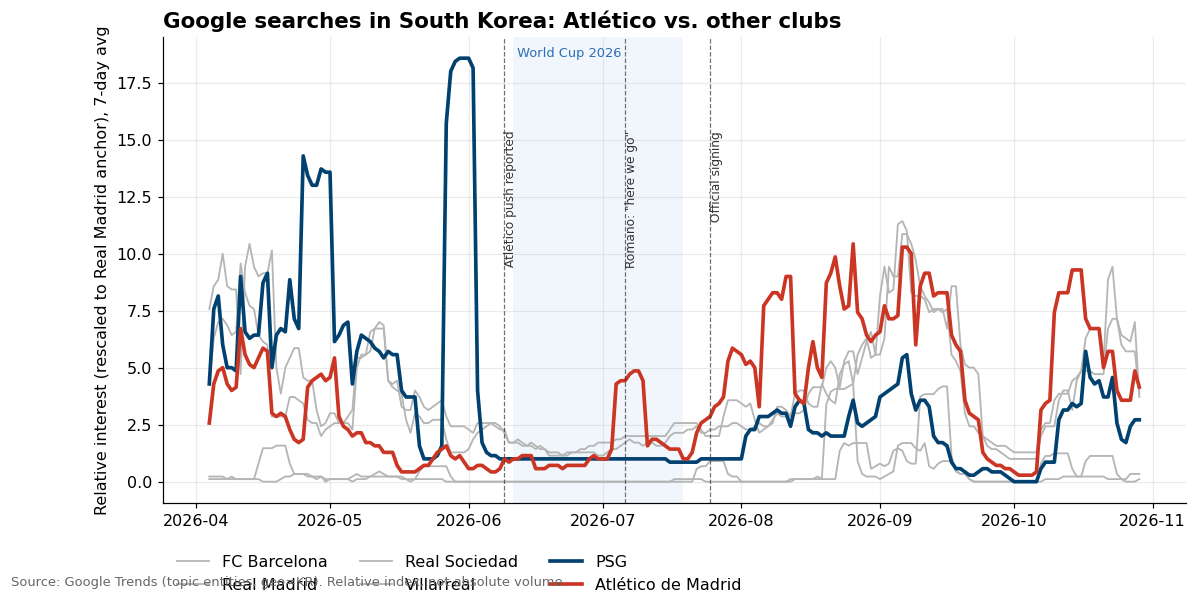

In [16]:
kr = trends[(trends.geo == 'KR') & (trends.granularity == 'daily')] \
        .pivot_table(index='date', columns='entity', values='interest').rolling(7, center=True).mean()

if kr.empty:
    print('No KR daily data yet.')
else:
    fig, ax = plt.subplots()
    for col in [c for c in kr.columns if c not in COLORS] + [c for c in ['psg', 'atletico'] if c in kr]:
        if col in ('kangin_lee', 'mallorca'):
            continue
        hi = col in COLORS
        ax.plot(kr.index, kr[col], color=color_for(col), lw=2.4 if hi else 1.2, label=ENTITIES[col]['label'])
    decorate(ax, kr.index.min(), kr.index.max(), events=True)
    ax.set_title('Google searches in South Korea: Atlético vs. other clubs')
    ax.set_ylabel('Relative interest (rescaled to Real Madrid anchor), 7-day avg')
    ax.legend(ncol=3, loc='upper left', bbox_to_anchor=(0, -0.08))
    source_note(fig, 'Google Trends (topic entities, geo=KR). Relative index, not absolute volume.')
    save_fig(fig, '04_trends_kr_daily')
    plt.show()

### Exploratory chart 5 — Same story in three markets
Atlético's interest relative to the average of the control clubs (ratio = 1 means "moves like the controls"). Dividing by the controls cancels out the general World Cup boost.

Saved kangin_lee_effect/figures/05_trends_relative_by_country.png


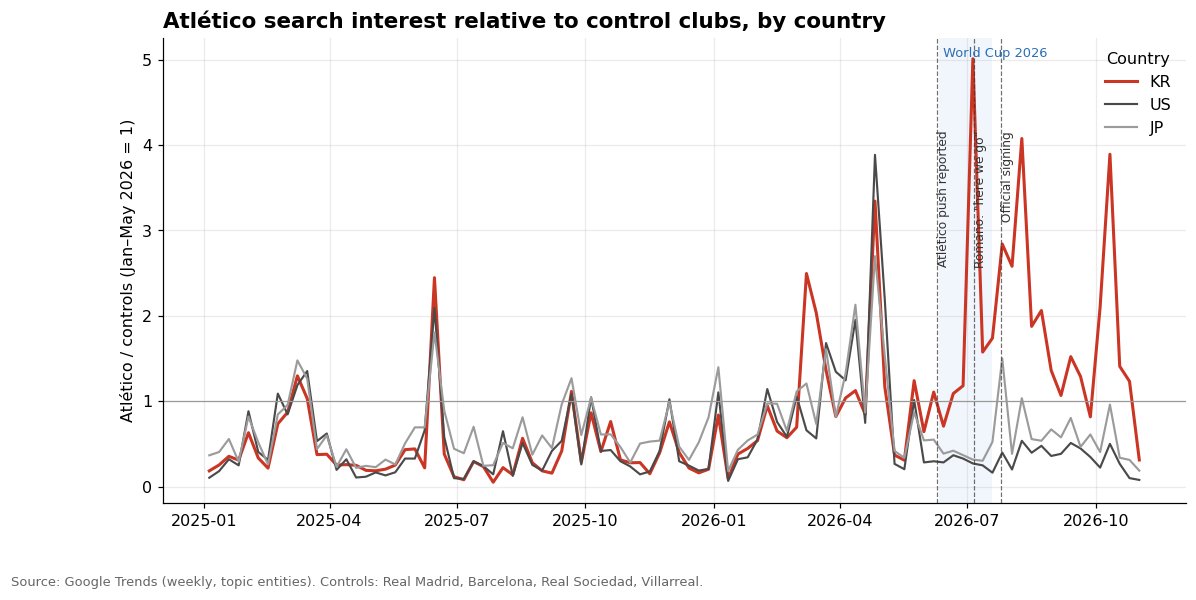

In [17]:
wk = trends[trends.granularity == 'weekly']
if wk.empty:
    print('No weekly data yet.')
else:
    fig, ax = plt.subplots()
    geo_colors = {'KR': '#CB3524', 'US': '#4A4A4A', 'JP': '#9B9B9B'}
    for geo in TRENDS_GEOS:
        g = wk[wk.geo == geo].pivot_table(index='date', columns='entity', values='interest')
        if 'atletico' not in g or g.empty:
            continue
        ctrl = g[[c for c in CONTROLS if c in g]].mean(axis=1)
        ratio = (g['atletico'] / ctrl).loc['2025-01-01':]
        ax.plot(ratio.index, ratio / ratio.loc[PRE_PERIOD[0]:PRE_PERIOD[1]].mean(), lw=2 if geo == 'KR' else 1.4,
                color=geo_colors[geo], label=geo)
    decorate(ax, '2025-01-01', END_DATE)
    ax.axhline(1, color='#999999', lw=0.8)
    ax.set_title('Atlético search interest relative to control clubs, by country')
    ax.set_ylabel('Atlético / controls (Jan–May 2026 = 1)')
    ax.legend(title='Country')
    source_note(fig, 'Google Trends (weekly, topic entities). Controls: Real Madrid, Barcelona, Real Sociedad, Villarreal.')
    save_fig(fig, '05_trends_relative_by_country')
    plt.show()

## 3. YouTube — Who is in the comments?

**Why it matters:** this is our audience-composition proxy. We can't know the nationality of Atlético's followers, but we *can* measure **what share of the comments under the club's videos are written in Korean**.

**Metric definition (decided before looking at the data):**
- **Korean comment share** = Korean-language comments / comments with text, counting only **top-level comments posted within 14 days of the video's upload**, grouped by the video's upload week.
- Why the 14-day window: a comment written in November under a January video says nothing about the January audience. Restricting to the first two weeks makes "before" and "after" comparable.
- Two classifier thresholds as a **sensitivity check**:
  - *strict*: at least 50% of the letters are Hangul (a comment written in Korean);
  - *broad*: at least 2 Hangul characters (includes mixed comments such as "Lee Kang-in 최고").
- **Channels:** Atlético (treatment), PSG (the club he left), Real Madrid (control with a large Asian audience).

**Quota:** the free YouTube API allows 10,000 units/day. The notebook estimates the cost before downloading, stops safely when it reaches the budget and **resumes where it left off** if you run it again the next day (use `USE_DRIVE = True` so progress survives).

In [18]:
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError

try:
    from google.colab import userdata
    YT_API_KEY = userdata.get('YOUTUBE_API_KEY')
except Exception:
    from getpass import getpass
    YT_API_KEY = getpass('YouTube API key (input hidden): ')

yt = build('youtube', 'v3', developerKey=YT_API_KEY, cache_discovery=False)

QUOTA_BUDGET = 9000        # units to spend in this run (daily limit is 10,000)
QUOTA = {'used': 0}

class QuotaBudgetReached(Exception):
    pass

def yt_call(request, cost=1):
    if QUOTA['used'] + cost > QUOTA_BUDGET:
        raise QuotaBudgetReached()
    QUOTA['used'] += cost
    return request.execute()

YouTube API key (input hidden): ··········


In [19]:
YT_START = '2026-01-01'          # videos uploaded from this date (pre-period starts here)
COMMENT_WINDOW_DAYS = 14
MAX_COMMENT_PAGES = 10           # 100 comments per page → up to 1,000 top-level comments per video

YT_CHANNELS = {
    'atletico':    {'handle': '@atleticodemadrid', 'channel_id': None},
    'psg':         {'handle': '@psg',              'channel_id': None},
    'real_madrid': {'handle': '@realmadrid',       'channel_id': None},
}

def resolve_channel(key, cfg):
    if cfg.get('channel_id'):
        res = yt_call(yt.channels().list(part='snippet,statistics,contentDetails', id=cfg['channel_id']))
    else:
        res = yt_call(yt.channels().list(part='snippet,statistics,contentDetails', forHandle=cfg['handle']))
    if not res.get('items'):
        found = yt_call(yt.search().list(part='snippet', q=ENTITIES[key]['label'], type='channel', maxResults=5), cost=100)
        print(f'⚠️ Could not resolve {key}. Candidates — copy the right channel_id into YT_CHANNELS:')
        for it in found['items']:
            print('   ', it['snippet']['channelId'], '|', it['snippet']['title'])
        return None
    it = res['items'][0]
    return {'entity': key, 'channel_id': it['id'], 'title': it['snippet']['title'],
            'country': it['snippet'].get('country'), 'subscribers': int(it['statistics'].get('subscriberCount', 0)),
            'videos': int(it['statistics'].get('videoCount', 0)),
            'uploads_playlist': it['contentDetails']['relatedPlaylists']['uploads']}

channels = pd.DataFrame([c for c in (resolve_channel(k, v) for k, v in YT_CHANNELS.items()) if c])
display(channels)   # ← CHECK: these must be the official club channels

,entity,channel_id,title,country,subscribers,videos,uploads_playlist
0,atletico,UCuzKFwdh7z2GHcIOX_tXgxA,Atlético de Madrid,None,12600000,7577,UUuzKFwdh7z2GHcIOX_tXgxA
1,psg,UCt9a_qP9CqHCNwilf-iULag,PSG - Paris Saint-Germain,FR,11000000,9579,UUt9a_qP9CqHCNwilf-iULag
2,real_madrid,UCWV3obpZVGgJ3j9FVhEjF2Q,Real Madrid,ES,21600000,9449,UUWV3obpZVGgJ3j9FVhEjF2Q


In [20]:
LEE_PATTERN = re.compile(r'kang[\s\-]?in|이강인|lee\s*kang|イ・ガンイン', re.IGNORECASE)

def list_uploads(playlist_id, since=YT_START):
    out, token = [], None
    while True:
        res = yt_call(yt.playlistItems().list(part='contentDetails', playlistId=playlist_id,
                                              maxResults=50, pageToken=token))
        page = [(it['contentDetails']['videoId'], it['contentDetails'].get('videoPublishedAt'))
                for it in res['items']]
        page = [(v, p) for v, p in page if p]                 # skip private/deleted
        out += [(v, p) for v, p in page if p >= since]
        token = res.get('nextPageToken')
        if not token or (page and all(p < since for _, p in page)):
            break
    return out

def video_details(video_ids):
    rows = []
    for i in range(0, len(video_ids), 50):
        res = yt_call(yt.videos().list(part='snippet,statistics,contentDetails', id=','.join(video_ids[i:i + 50])))
        for it in res['items']:
            sn, st = it['snippet'], it.get('statistics', {})
            text = sn.get('title', '') + ' ' + sn.get('description', '')
            dur = pd.Timedelta(it['contentDetails'].get('duration', 'PT0S')).total_seconds()
            rows.append({'video_id': it['id'], 'published_at': sn['publishedAt'], 'title': sn.get('title', ''),
                         'duration_s': dur, 'is_short': dur <= 180,   # Shorts can last up to 3 min
                         'views': int(st.get('viewCount', 0)), 'likes': int(st.get('likeCount', 0)),
                         'comment_count': int(st.get('commentCount', 0)) if 'commentCount' in st else None,
                         'mentions_lee': bool(LEE_PATTERN.search(text))})
    return rows

VIDEOS_PATH = RAW_DIR / 'youtube_videos.csv'
if cached(VIDEOS_PATH):
    videos = pd.read_csv(VIDEOS_PATH, parse_dates=['published_at'])
    print('Loaded cached', VIDEOS_PATH)
else:
    frames = []
    for _, ch in channels.iterrows():
        ups = list_uploads(ch.uploads_playlist)
        det = pd.DataFrame(video_details([v for v, _ in ups])).assign(entity=ch.entity)
        frames.append(det)
        print(f'✓ {ch.entity}: {len(det)} videos since {YT_START}')
    videos = pd.concat(frames, ignore_index=True)
    videos['published_at'] = pd.to_datetime(videos['published_at'])
    videos.to_csv(VIDEOS_PATH, index=False)

print('Quota used so far:', QUOTA['used'])
videos.groupby('entity').agg(videos=('video_id', 'size'), shorts=('is_short', 'sum'),
                             mention_lee=('mentions_lee', 'sum'), comments=('comment_count', 'sum'))

✓ atletico: 1332 videos since 2026-01-01
✓ psg: 948 videos since 2026-01-01
✓ real_madrid: 1091 videos since 2026-01-01
Quota used so far: 142


,videos,shorts,mention_lee,comments
entity,,,,
atletico,1332,1147,37,34022
psg,948,655,15,139507
real_madrid,1091,943,1,338100


### Quota estimate before downloading comments
Cost ≈ one unit per page of 100 comments. We estimate it from each video's comment count, so you know in advance how many days the download will take.

In [21]:
def pages_needed(c):
    if c is None or pd.isna(c) or c == 0:
        return 0
    return int(min(math.ceil(c / 100), MAX_COMMENT_PAGES))

videos['est_pages'] = videos['comment_count'].apply(pages_needed)
est = videos.groupby('entity').est_pages.sum()
display(est.rename('estimated_units'))
total = int(est.sum())
print(f'Total ≈ {total:,} units → about {math.ceil(total / QUOTA_BUDGET)} day(s) at {QUOTA_BUDGET:,} units/day.')
print('Tip: if it is too much, drop the control channel or move YT_START later — but keep at least 3 months of pre-period.')

,estimated_units
entity,
atletico,1417
psg,1832
real_madrid,3558


Total ≈ 6,807 units → about 1 day(s) at 9,000 units/day.
Tip: if it is too much, drop the control channel or move YT_START later — but keep at least 3 months of pre-period.


### Korean-language classifier
Simple, transparent and testable: count Hangul characters among the letters of the comment. Emoji-only comments have no letters and are excluded from the denominator (reported separately).

In [22]:
HANGUL_RE = re.compile(r'[\u1100-\u11FF\u3130-\u318F\uAC00-\uD7A3]')
LETTER_RE = re.compile(r'[^\W\d_]', re.UNICODE)

def hangul_stats(text):
    text = text or ''
    n_letters = len(LETTER_RE.findall(text))
    n_hangul = len(HANGUL_RE.findall(text))
    return n_letters, n_hangul

def classify(text, strict_threshold=0.5, broad_min_chars=2):
    n_letters, n_hangul = hangul_stats(text)
    if n_letters == 0:
        return {'n_letters': 0, 'n_hangul': 0, 'ko_strict': None, 'ko_broad': None}
    return {'n_letters': n_letters, 'n_hangul': n_hangul,
            'ko_strict': n_hangul / n_letters >= strict_threshold,
            'ko_broad': n_hangul >= broad_min_chars}

# Unit tests — the classifier must pass these before we trust it
TESTS = [
    ('이강인 화이팅!!', True, True),
    ('Vamos Atleti 🔴⚪', False, False),
    ('Lee Kang-in 최고', False, True),        # mixed: only the broad rule counts it
    ('아틀레티코 마드리드 응원합니다 from Seoul', True, True),
    ('🔥🔥🔥', None, None),
    ('イ・ガンイン最高', False, False),          # Japanese is not Korean
    ('Golazo de Griezmann', False, False),
]
for text, exp_strict, exp_broad in TESTS:
    r = classify(text)
    assert (r['ko_strict'], r['ko_broad']) == (exp_strict, exp_broad), (text, r)
print(f'✓ Classifier passed {len(TESTS)} tests')

✓ Classifier passed 7 tests


In [23]:
COMMENTS_PATH = RAW_DIR / 'youtube_comments.csv'
STATUS_PATH = RAW_DIR / 'youtube_comment_status.csv'
STORE_TEXT = True     # comment text is kept for manual QA; no author names or IDs are stored

def fetch_window_comments(video_id, published_at):
    window_end = published_at + pd.Timedelta(days=COMMENT_WINDOW_DAYS)
    rows, token, pages = [], None, 0
    while pages < MAX_COMMENT_PAGES:
        try:
            res = yt_call(yt.commentThreads().list(part='snippet', videoId=video_id, maxResults=100,
                                                   order='time', textFormat='plainText', pageToken=token))
        except HttpError as e:
            msg = str(e)
            if 'quotaExceeded' in msg or 'dailyLimitExceeded' in msg:
                raise QuotaBudgetReached()
            return rows, ('disabled' if 'commentsDisabled' in msg else f'error_{e.resp.status}'), pages
        pages += 1
        for it in res['items']:
            s = it['snippet']['topLevelComment']['snippet']
            ts = pd.Timestamp(s['publishedAt'])
            if ts <= window_end:
                c = classify(s.get('textDisplay', ''))
                rows.append({'comment_id': it['id'], 'video_id': video_id, 'comment_at': s['publishedAt'],
                             'likes': s.get('likeCount', 0), 'replies': it['snippet'].get('totalReplyCount', 0),
                             **c, 'text': s.get('textDisplay', '') if STORE_TEXT else None})
        token = res.get('nextPageToken')
        if not token:
            return rows, 'complete', pages
    return rows, 'truncated', pages

done = set(pd.read_csv(STATUS_PATH).video_id) if Path(STATUS_PATH).exists() and not FORCE_REFRESH else set()
todo = videos[(~videos.video_id.isin(done)) & (videos.est_pages > 0)].sort_values('published_at')
print(f'{len(done)} videos already processed, {len(todo)} to go.')

n_new = 0
try:
    for _, v in todo.iterrows():
        rows, status, pages = fetch_window_comments(v.video_id, pd.Timestamp(v.published_at))
        if rows:
            pd.DataFrame(rows).assign(entity=v.entity).to_csv(
                COMMENTS_PATH, mode='a', index=False, header=not Path(COMMENTS_PATH).exists())
        pd.DataFrame([{'video_id': v.video_id, 'entity': v.entity, 'status': status, 'pages': pages,
                       'n_window_comments': len(rows)}]).to_csv(
            STATUS_PATH, mode='a', index=False, header=not Path(STATUS_PATH).exists())
        n_new += 1
        if n_new % 50 == 0:
            print(f'   {n_new} videos | quota used {QUOTA["used"]:,}')
    print('✓ All videos processed.')
except QuotaBudgetReached:
    print(f'⏸ Budget reached after {n_new} videos. Run this cell again tomorrow — it resumes automatically.')
print('Quota used in this run:', QUOTA['used'])

0 videos already processed, 3351 to go.
   50 videos | quota used 219
   100 videos | quota used 326
   150 videos | quota used 462
   200 videos | quota used 570
   250 videos | quota used 661
   300 videos | quota used 753
   350 videos | quota used 853
   400 videos | quota used 957
   450 videos | quota used 1,028
   500 videos | quota used 1,117
   550 videos | quota used 1,198
   600 videos | quota used 1,274
   650 videos | quota used 1,346
   700 videos | quota used 1,423
   750 videos | quota used 1,497
   800 videos | quota used 1,566
   850 videos | quota used 1,662
   900 videos | quota used 1,758
   950 videos | quota used 1,844
   1000 videos | quota used 1,926
   1050 videos | quota used 2,009
   1100 videos | quota used 2,077
   1150 videos | quota used 2,161
   1200 videos | quota used 2,256
   1250 videos | quota used 2,360
   1300 videos | quota used 2,437
   1350 videos | quota used 2,502
   1400 videos | quota used 2,582
   1450 videos | quota used 2,657
   1500 vi

### QA: coverage and classifier spot-check
- **Coverage:** videos marked `truncated` have more than 1,000 comments, so their 14-day window may be incomplete. They are excluded from the metric and the table shows how many there are; if they are concentrated after the signing, raise `MAX_COMMENT_PAGES`.
- **Spot-check:** read 20 random comments classified as Korean and 20 as non-Korean. If you find errors, adjust the thresholds before Phase 2.

In [24]:
status = pd.read_csv(STATUS_PATH) if Path(STATUS_PATH).exists() else pd.DataFrame()
comments = pd.read_csv(COMMENTS_PATH, parse_dates=['comment_at']) if Path(COMMENTS_PATH).exists() else pd.DataFrame()

if status.empty:
    print('No comments downloaded yet.')
else:
    display(status.pivot_table(index='entity', columns='status', values='video_id', aggfunc='count', fill_value=0))
    sample_ko = comments[comments.ko_strict == True].sample(min(20, (comments.ko_strict == True).sum()), random_state=1)
    sample_other = comments[comments.ko_strict == False].sample(min(20, (comments.ko_strict == False).sum()), random_state=1)
    print('\n— Classified as Korean (strict) —')
    for t in sample_ko.text: print('  ', str(t)[:110].replace('\n', ' '))
    print('\n— Classified as NOT Korean —')
    for t in sample_other.text: print('  ', str(t)[:110].replace('\n', ' '))

status,complete,truncated
entity,,
atletico,1320,1
psg,938,8
real_madrid,1053,31


In [25]:
# Per-video metric → weekly series (by video upload week)
if not comments.empty:
    ok_videos = status[status.status == 'complete'].video_id
    per_video = (comments[comments.video_id.isin(ok_videos) & comments.ko_strict.notna()]
                 .groupby(['entity', 'video_id'])
                 .agg(n_text=('ko_strict', 'size'),
                      n_ko_strict=('ko_strict', lambda s: int(s.astype(bool).sum())),
                      n_ko_broad=('ko_broad', lambda s: int(s.astype(bool).sum())))
                 .reset_index()
                 .merge(videos[['video_id', 'published_at', 'is_short', 'mentions_lee', 'views']], on='video_id'))
    per_video.to_csv(PROC_DIR / 'youtube_korean_share_per_video.csv', index=False)

    weekly = (per_video.assign(week=lambda d: d.published_at.dt.tz_localize(None).dt.to_period('W').dt.start_time)
                       .groupby(['entity', 'week'])
                       .agg(videos=('video_id', 'size'), n_text=('n_text', 'sum'),
                            n_ko_strict=('n_ko_strict', 'sum'), n_ko_broad=('n_ko_broad', 'sum'))
                       .assign(share_strict=lambda d: d.n_ko_strict / d.n_text,
                               share_broad=lambda d: d.n_ko_broad / d.n_text)
                       .reset_index())
    weekly.to_csv(PROC_DIR / 'youtube_korean_share_weekly.csv', index=False)
    display(weekly.groupby('entity')[['videos', 'n_text']].sum())

,videos,n_text
entity,,
atletico,1304,22275
psg,938,83473
real_madrid,1053,208989


### Exploratory chart 6 — Share of Korean comments under each club's videos
Weighted by number of comments per week. The shaded band is the broad/strict range: if both lines tell the same story, the result does not depend on the threshold.

Saved kangin_lee_effect/figures/06_youtube_korean_share.png


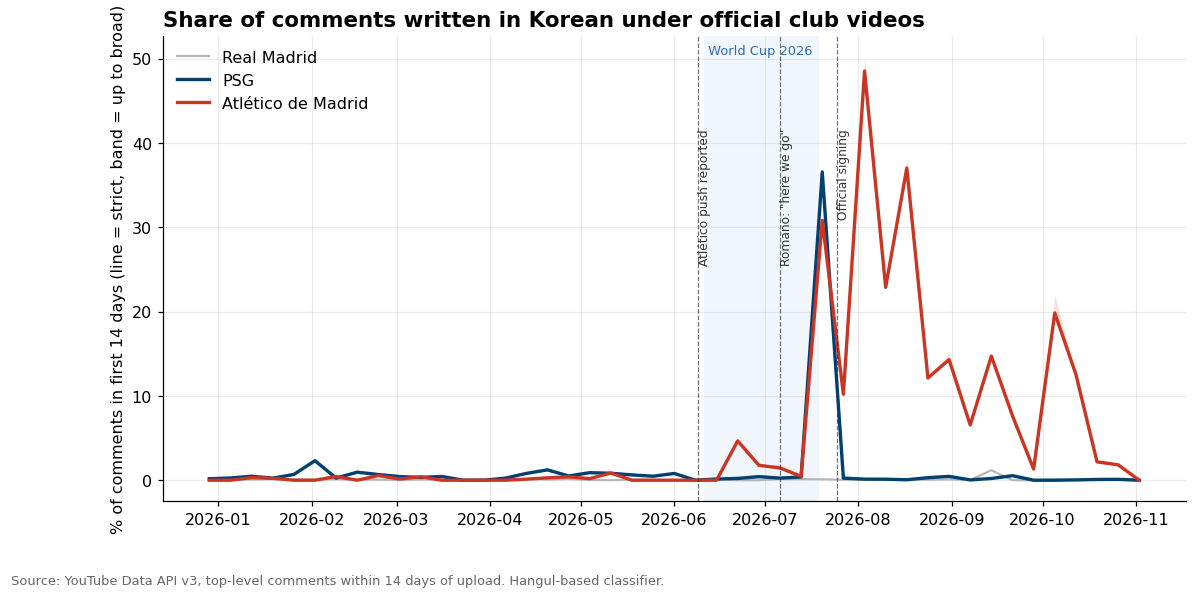

In [26]:
if not comments.empty:
    fig, ax = plt.subplots()
    for ent in ['real_madrid', 'psg', 'atletico']:
        w = weekly[weekly.entity == ent].set_index('week').sort_index()
        if w.empty:
            continue
        ax.fill_between(w.index, w.share_strict * 100, w.share_broad * 100, color=color_for(ent), alpha=0.15, lw=0)
        ax.plot(w.index, w.share_strict * 100, color=color_for(ent), lw=2.2 if ent in COLORS else 1.4,
                label=ENTITIES[ent]['label'])
    decorate(ax, YT_START, END_DATE)
    ax.set_title('Share of comments written in Korean under official club videos')
    ax.set_ylabel('% of comments in first 14 days (line = strict, band = up to broad)')
    ax.legend(loc='upper left')
    source_note(fig, 'YouTube Data API v3, top-level comments within 14 days of upload. Hangul-based classifier.')
    save_fig(fig, '06_youtube_korean_share')
    plt.show()

In [27]:
# Before/after summary + videos featuring Lee vs. the rest (Atlético only, after the signing)
if not comments.empty:
    signing = pd.Timestamp('2026-07-25', tz='UTC')
    pv = per_video.copy()
    pv['period'] = np.where(pv.published_at < pd.Timestamp(PRE_PERIOD[1], tz='UTC') + pd.Timedelta(days=1), 'pre (Jan–May)',
                   np.where(pv.published_at >= signing, 'post (from signing)', 'transition (Jun–Jul)'))
    summary = (pv.groupby(['entity', 'period'])[['n_text', 'n_ko_strict', 'n_ko_broad']].sum()
                 .assign(share_strict_pct=lambda d: (d.n_ko_strict / d.n_text * 100).round(2),
                         share_broad_pct=lambda d: (d.n_ko_broad / d.n_text * 100).round(2)))
    display(summary)

    atl_post = pv[(pv.entity == 'atletico') & (pv.published_at >= signing)]
    by_lee = (atl_post.groupby('mentions_lee')[['n_text', 'n_ko_strict']].sum()
                      .assign(share_pct=lambda d: (d.n_ko_strict / d.n_text * 100).round(2)))
    by_lee.index = by_lee.index.map({True: 'Videos featuring Lee', False: 'Other videos'})
    display(by_lee)

n_text  n_ko_strict  n_ko_broad  share_strict_pct  share_broad_pct
entity      period                                                                                  
atletico    post (from signing)     9327         2121        2182             22.74            23.39
            pre (Jan–May)          11355           21          21              0.18             0.18
            transition (Jun–Jul)    1593           20          21              1.26             1.32
psg         post (from signing)    29783          515         523              1.73             1.76
            pre (Jan–May)          46623          314         322              0.67             0.69
            transition (Jun–Jul)    7067           34          34              0.48             0.48
real_madrid post (from signing)    83695          107         110              0.13             0.13
            pre (Jan–May)          97137           76          75              0.08             0.08
            transition (Jun–Jul)   28157           27          27              0.10             0.10

,n_text,n_ko_strict,share_pct
mentions_lee,,,
Other videos,6360,501,7.88
Videos featuring Lee,2967,1620,54.60


## 4. Instagram & X — manual capture (no paid tools)

What we **can** do legitimately and for free:

**4a. Total followers over time.** Not by country (nobody outside the club can see that), but a jump around 25 July that the control clubs did *not* have is still evidence.
- Sources: Social Blade's public profile pages (free history is limited) and, for older points, **Wayback Machine** snapshots of those pages (web.archive.org → paste the Social Blade URL → pick dates before and after the signing).
- Record each point in the template below, **with the URL you took it from**. That URL is your citation if someone asks.
- Aim for at least: ~1 Jan, ~1 May, ~1 Jul, ~1 Aug, ~1 Sep, today — for Atlético and 2–3 control clubs.

**4b. Instagram comment sample.** Pick 10 posts before (Jan–May) and 10 after the signing, matched by type (e.g. match result posts). For each one, copy the comments you can see into the `classify_pasted_comments` helper: it applies **the same classifier** as YouTube, so the numbers are consistent. No scraping, no usernames.

In [28]:
FOLLOWERS_PATH = MANUAL_DIR / 'social_followers_manual.csv'
IG_SAMPLE_PATH = MANUAL_DIR / 'instagram_comment_sample_manual.csv'

if not FOLLOWERS_PATH.exists():
    pd.DataFrame(columns=['date', 'platform', 'entity', 'followers', 'source_url', 'captured_on']).to_csv(FOLLOWERS_PATH, index=False)
if not IG_SAMPLE_PATH.exists():
    pd.DataFrame(columns=['post_url', 'post_date', 'post_type', 'period', 'n_comments', 'n_with_text',
                          'n_ko_strict', 'n_ko_broad']).to_csv(IG_SAMPLE_PATH, index=False)
print('Templates ready in', MANUAL_DIR)
print('Fill', FOLLOWERS_PATH.name, '— entity must be one of:', list(ENTITIES))

def classify_pasted_comments(block, post_url=None, post_date=None, post_type=None, period=None, save=False):
    # One comment per line. Lines that are just usernames/timestamps can be left in: they have no Hangul
    # but DO count as text, so remove them if the copy includes them.
    lines = [l.strip() for l in block.splitlines() if l.strip()]
    res = [classify(l) for l in lines]
    with_text = [r for r in res if r['ko_strict'] is not None]
    row = {'post_url': post_url, 'post_date': post_date, 'post_type': post_type, 'period': period,
           'n_comments': len(lines), 'n_with_text': len(with_text),
           'n_ko_strict': sum(r['ko_strict'] for r in with_text),
           'n_ko_broad': sum(r['ko_broad'] for r in with_text)}
    if save:
        pd.DataFrame([row]).to_csv(IG_SAMPLE_PATH, mode='a', index=False, header=False)
    return row

# Example:
classify_pasted_comments('''이강인 화이팅
Aupa Atleti!!
🔥🔥
최고의 선수''')

Templates ready in kangin_lee_effect/data/manual
Fill social_followers_manual.csv — entity must be one of: ['atletico', 'psg', 'mallorca', 'real_madrid', 'barcelona', 'real_sociedad', 'villarreal', 'kangin_lee']


{'post_url': None,
 'post_date': None,
 'post_type': None,
 'period': None,
 'n_comments': 4,
 'n_with_text': 3,
 'n_ko_strict': 2,
 'n_ko_broad': 2}

In [29]:
followers = pd.read_csv(FOLLOWERS_PATH, parse_dates=['date'])
if len(followers) < 4:
    print('Add follower snapshots to the template to see this chart.')
else:
    for platform, g in followers.groupby('platform'):
        fig, ax = plt.subplots(figsize=(11, 4.5))
        for ent, s in g.groupby('entity'):
            s = s.sort_values('date').set_index('date').followers.astype(float)
            base = s[s.index <= pd.Timestamp(PRE_PERIOD[1])]
            if base.empty:
                continue
            ax.plot(s.index, (s / base.iloc[-1] - 1) * 100, marker='o', color=color_for(ent),
                    lw=2.2 if ent in COLORS else 1.2, label=ENTITIES.get(ent, {'label': ent})['label'])
        decorate(ax, followers.date.min(), followers.date.max())
        ax.set_title(f'{platform}: follower growth since end of May 2026')
        ax.set_ylabel('% change vs. last pre-period snapshot')
        ax.legend(loc='upper left')
        source_note(fig, 'Manual snapshots (Social Blade / Wayback Machine). URLs in social_followers_manual.csv.')
        save_fig(fig, f'07_followers_{platform.lower()}')
        plt.show()

Add follower snapshots to the template to see this chart.


## 5. Data inventory

Everything Phase 2 needs, with row counts and date ranges, so you can confirm nothing is missing before modelling.

In [30]:
inventory = []
for path in sorted(BASE_DIR.glob('data/**/*.csv')):
    try:
        df = pd.read_csv(path)
        date_col = next((c for c in ['date', 'week', 'published_at', 'comment_at'] if c in df.columns), None)
        rng = (str(df[date_col].min())[:10], str(df[date_col].max())[:10]) if date_col and len(df) else ('', '')
        inventory.append({'file': str(path.relative_to(BASE_DIR)), 'rows': len(df), 'from': rng[0], 'to': rng[1]})
    except Exception as e:
        inventory.append({'file': str(path.relative_to(BASE_DIR)), 'rows': None, 'from': '', 'to': f'error: {e}'})
display(pd.DataFrame(inventory))
print('Figures:', [p.name for p in sorted(FIG_DIR.glob('*.png'))])

,file,rows,from,to
0,data/manual/instagram_comment_sample_manual.csv,0,,
1,data/manual/social_followers_manual.csv,0,,
2,data/processed/youtube_korean_share_per_video.csv,3295,2026-01-01,2026-11-02
3,data/processed/youtube_korean_share_weekly.csv,135,2025-12-29,2026-11-02
4,data/raw/google_trends.csv,11256,2021-12-26,2026-11-01
5,data/raw/wikipedia_pageviews.csv,42384,2022-01-01,2026-11-01
6,data/raw/youtube_comment_status.csv,3351,,
7,data/raw/youtube_comments.csv,382930,2026-01-01,2026-11-02
8,data/raw/youtube_videos.csv,3371,2026-01-01,2026-11-02


Figures: ['01_ko_wikipedia_clubs_indexed.png', '02_ko_wikipedia_player_vs_club.png', '03_validation_2023_psg.png', '04_trends_kr_daily.png', '05_trends_relative_by_country.png', '06_youtube_korean_share.png']


### Data dictionary

| File | Grain | Key columns |
|---|---|---|
| `raw/wikipedia_pageviews.csv` | entity × language × day | `views` (user agents only), `api_days_present` |
| `raw/wikipedia_titles.json` | entity | Resolved article title per language |
| `raw/google_trends.csv` | entity × country × period | `interest` (rescaled to Real Madrid anchor), `granularity` |
| `raw/youtube_videos.csv` | video | `published_at`, `views`, `comment_count`, `is_short`, `mentions_lee` |
| `raw/youtube_comments.csv` | top-level comment (≤14 days after upload) | `ko_strict`, `ko_broad`, `n_hangul`, `n_letters` — no author data |
| `raw/youtube_comment_status.csv` | video | `status` (complete / truncated / disabled / error) |
| `processed/youtube_korean_share_per_video.csv` | video | Korean comment counts per video |
| `processed/youtube_korean_share_weekly.csv` | entity × upload week | `share_strict`, `share_broad` |
| `manual/social_followers_manual.csv` | snapshot | `followers`, `source_url` |
| `manual/instagram_comment_sample_manual.csv` | post | Korean comment counts per sampled post |

### Next: Phase 2
1. **Difference-in-differences** on Korean Wikipedia views and Korean comment share (Atlético vs. controls, pre vs. post).
2. **CausalImpact** on daily Korean Wikipedia views, with control clubs as covariates → the "actual vs. counterfactual" hero chart.
3. **Validation:** the same model on the 2023 Mallorca → PSG transfer.
4. **Player-vs-club test:** did PSG lose Korean attention when Atlético gained it?